# Прогноз качества вина по CRISP-DM

Можно ли по лабораторным измерениям предсказать дегустационную оценку красного и белого португальского вина Vinho Verde? Эксперимент использует `winequalityN.csv` из набора Wine Quality на Kaggle. [Kaggle, `rajyellow46/wine-quality`](https://www.kaggle.com/datasets/rajyellow46/wine-quality)

**Результат.** Случайный лес предсказывает оценку со средней абсолютной ошибкой **0,538 балла** на 1 059 тестовых образцах. Это на **16,4 %** меньше, чем у медианного прогноза. На редких крайних оценках ошибки выше.

Код и результаты сохранены в ноутбуке. Для пересчёта запустите все ячейки сверху вниз в Jupyter или Colab. Первая загрузка обращается к публичному API Kaggle без токена. Если сеть недоступна, положите исходный `winequalityN.csv` в рабочую папку ноутбука.

<details>
<summary>Версии для воспроизведения</summary>

Проверено в Python 3.12. При необходимости запустите команду в отдельной ячейке и перезапустите ядро перед пересчётом.

```python
%pip install numpy==2.2.6 pandas==2.2.3 scipy==1.15.3 scikit-learn==1.7.2 matplotlib==3.10.3 joblib==1.5.1
```

</details>

## 1. Понимание бизнес-задачи

**Сценарий.** Лаборатория получает химический профиль образца и хочет заранее оценить, какой балл может поставить дегустационная комиссия. Прогноз помогает распределить время дегустаторов. Решение о качестве принимает комиссия.

`quality` — целочисленный балл от 0 до 10 по описанию источника. Постановка как регрессия учитывает порядок баллов и размер промаха. Ошибка между 5 и 6 обходится дешевле, чем между 5 и 8.

**Критерий успеха для этого эксперимента.** Снизить MAE на отложенном тесте минимум на 10 % относительно простого прогноза медианы на обучении. MAE измеряется в баллах и трактуется как средний размер промаха. Дополнительно посчитаем RMSE, которая сильнее штрафует крупные ошибки, и разберём результаты по типу вина и фактической оценке.

## 2. Понимание данных

Каждая строка содержит тип вина (`red` или `white`), 11 числовых измерений и балл `quality`. Среди измерений есть кислотность, остаточный сахар, хлориды, свободный и общий диоксид серы, плотность, pH, сульфаты и алкоголь. В версии Kaggle объединены красные и белые вина из UCI, а часть значений удалена. [Описание исходного набора UCI](https://doi.org/10.24432/C56S3T)

In [1]:
import hashlib
import os
import platform
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

os.environ.setdefault("OMP_NUM_THREADS", "2")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Markdown, display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

%matplotlib inline

SEED = 42
TARGET = "quality"
DATA_URL = (
    "https://api.kaggle.com/v1/datasets/download/rajyellow46/wine-quality"
    "?datasetVersionNumber=1"
)
CSV_PATH = Path("winequalityN.csv")
CSV_SHA256 = "cb01f91c70de066f85d4cffac3bb163e4719523861cd79ba8825b722cf98b48c"

if CSV_PATH.is_file():
    csv_bytes = CSV_PATH.read_bytes()
else:
    with urlopen(DATA_URL, timeout=45) as response:
        archive_bytes = response.read()
    with ZipFile(BytesIO(archive_bytes)) as archive:
        csv_bytes = archive.read(CSV_PATH.name)

if hashlib.sha256(csv_bytes).hexdigest() != CSV_SHA256:
    raise ValueError("Требуется исходный winequalityN.csv из версии 1 на Kaggle.")

raw = pd.read_csv(BytesIO(csv_bytes))
print(f"Python {platform.python_version()} • scikit-learn {sklearn.__version__}")
print(f"{len(raw):,} строк × {raw.shape[1]} столбцов".replace(",", " "))
display(raw.head(3))

Python 3.12.14 • scikit-learn 1.7.2
6 497 строк × 13 столбцов


,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6


In [2]:
missing = raw.isna().sum()
missing_table = missing[missing.gt(0)].rename("Пропусков").to_frame()
missing_table["Доля строк, %"] = 100 * missing_table["Пропусков"] / len(raw)
incomplete = raw[raw.isna().any(axis=1)].drop(columns=TARGET)
complete_profiles = raw.dropna().drop(columns=TARGET).drop_duplicates()
possible_repeats = 0
for _, row in incomplete.iterrows():
    known = row.dropna()
    if complete_profiles[known.index].eq(known).all(axis=1).any():
        possible_repeats += 1

print(f"Строки с пропусками: {len(incomplete)}")
print(f"Точные повторы: {raw.duplicated().sum()}")
print(f"Неполные профили, совпавшие с полными по известным признакам: {possible_repeats}")
display(missing_table.round(2))
display(pd.crosstab(raw[TARGET], raw["type"]).rename_axis("Оценка", axis=0))

Строки с пропусками: 34
Точные повторы: 1168
Неполные профили, совпавшие с полными по известным признакам: 9


,Пропусков,"Доля строк, %"
fixed acidity,10,0.15
volatile acidity,8,0.12
citric acid,3,0.05
residual sugar,2,0.03
chlorides,2,0.03
pH,9,0.14
sulphates,4,0.06


type,red,white
Оценка,,
3,10,20
4,53,163
5,681,1457
6,638,2198
7,199,880
8,18,175
9,0,5


Баллы 5 и 6 встречаются чаще остальных. В исходных данных всего 30 оценок 3 и пять оценок 9, поэтому точность на краях шкалы будет оценена по небольшому числу примеров.

## 3. Подготовка данных

Удаляем полные повторы и строки с пропусками. У 34 неполных строк отсутствует хотя бы одно измерение, а девять из них совпадают с полными записями по всем известным признакам. Исключение этих строк уменьшает риск попадания копий одного профиля в обучение и тест. Проверяем, что полные очищенные профили уникальны по всем входным признакам.

Отводим 20 % очищенной выборки под тест, сохраняя распределение целых оценок. Для пяти фолдов внутри обучения объединяем редкие крайние значения с соседями только при стратификации. Модели по-прежнему обучаются на исходных баллах.

In [3]:
clean = raw.dropna().drop_duplicates().reset_index(drop=True)
X = clean.drop(columns=TARGET)
y = clean[TARGET]
numeric_features = X.select_dtypes(include="number").columns.tolist()

assert not X.duplicated().any(), "Профили с совпадающими признаками должны быть в одном сплите."
assert len(numeric_features) == 11 and set(X["type"]) == {"red", "white"}

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(cv.split(X_train, y_train.clip(lower=4, upper=8)))

print(f"После очистки: {len(clean)} профилей. Обучение: {len(X_train)}. Тест: {len(X_test)}.")
split_counts = pd.DataFrame({
    "Обучение": y_train.value_counts(),
    "Тест": y_test.value_counts(),
}).sort_index().rename_axis("Оценка")
display(split_counts.T)

После очистки: 5295 профилей. Обучение: 4236. Тест: 1059.


Оценка,3,4,5,6,7,8,9
Обучение,24,163,1396,1849,682,118,4
Тест,6,41,349,462,170,30,1


### Разведочный анализ обучающей выборки

Доли рассчитаны внутри каждого типа вина. Коэффициент Спирмена показывает направление и силу монотонной связи признака с оценкой. Связь может отражать различия между образцами и сама по себе не устанавливает причинность.

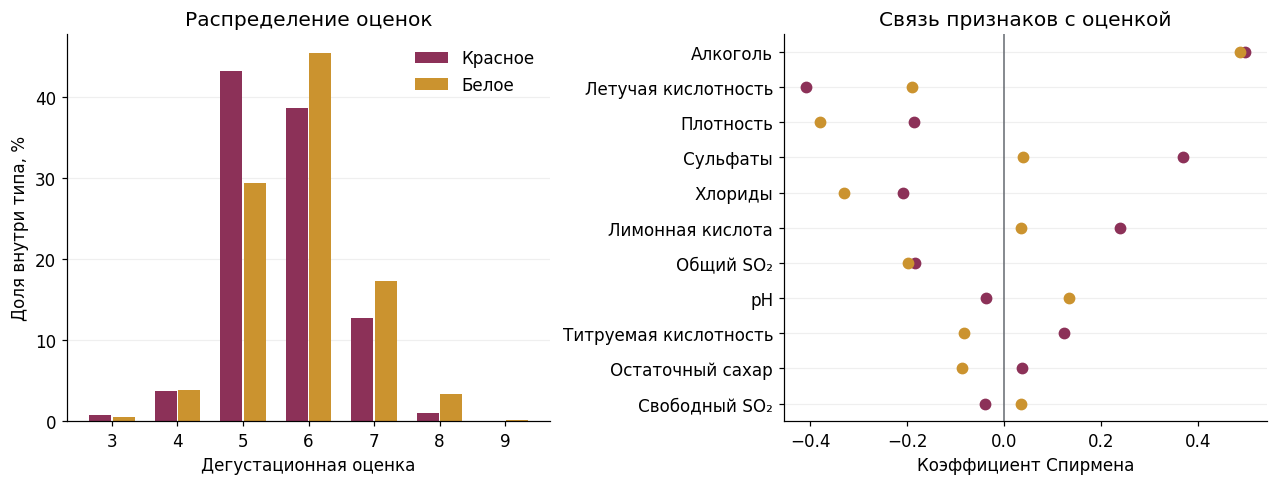

In [4]:
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.axisbelow": True,
    "figure.dpi": 110,
    "savefig.facecolor": "white",
})
colors = {"red": "#8C3158", "white": "#CB932F"}
labels = {"red": "Красное", "white": "Белое"}
features_ru = {
    "fixed acidity": "Титруемая кислотность",
    "volatile acidity": "Летучая кислотность",
    "citric acid": "Лимонная кислота",
    "residual sugar": "Остаточный сахар",
    "chlorides": "Хлориды",
    "free sulfur dioxide": "Свободный SO₂",
    "total sulfur dioxide": "Общий SO₂",
    "density": "Плотность",
    "pH": "pH",
    "sulphates": "Сульфаты",
    "alcohol": "Алкоголь",
    "type": "Тип вина",
}
train = X_train.assign(quality=y_train)
shares = 100 * pd.crosstab(train[TARGET], train["type"], normalize="columns")
spearman = pd.DataFrame({
    wine_type: group[numeric_features].corrwith(group[TARGET], method="spearman")
    for wine_type, group in train.groupby("type")
})
spearman = spearman.loc[spearman.abs().max(axis=1).sort_values().index]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3), layout="constrained")
for wine_type, offset in [("red", -0.18), ("white", 0.18)]:
    axes[0].bar(shares.index + offset, shares[wine_type], width=0.34,
                color=colors[wine_type], label=labels[wine_type])
    axes[1].scatter(spearman[wine_type], spearman.index.map(features_ru),
                    color=colors[wine_type], s=45, label=labels[wine_type])

axes[0].set(title="Распределение оценок", xlabel="Дегустационная оценка",
            ylabel="Доля внутри типа, %", xticks=shares.index)
axes[0].grid(axis="y", alpha=0.2)
axes[0].legend(frameon=False)
axes[1].axvline(0, color="#646970", linewidth=1)
axes[1].set(title="Связь признаков с оценкой", xlabel="Коэффициент Спирмена")
axes[1].grid(axis="y", alpha=0.2)
plt.show()

Для обоих типов вина алкоголь положительно связан с оценкой, а летучая кислотность — отрицательно. Сила связи зависит от типа, поэтому оставляем `type` среди входных признаков.

Для всех моделей используем one-hot-кодирование типа вина. Масштабирование числовых признаков нужно Ridge, поскольку величина штрафа зависит от шкалы коэффициентов. Преобразования входят в `Pipeline` и обучаются заново внутри каждого фолда.

In [5]:
def make_pipeline(model, *, scale_numeric=False):
    preprocess = ColumnTransformer([
        ("number", StandardScaler() if scale_numeric else "passthrough", numeric_features),
        ("wine_type", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["type"]),
    ])
    return Pipeline([("preprocess", preprocess), ("model", model)])

## 4. Моделирование

Сравниваем четыре подхода на одних и тех же пяти фолдах. Медианный прогноз задаёт базовый уровень. Ridge проверяет линейную зависимость. Случайный лес и градиентный бустинг моделируют нелинейные связи между химическими показателями и оценкой.

Гиперпараметры и итоговая модель выбираются по минимальной средней MAE кросс-валидации. `GridSearchCV` затем переобучает лучший вариант каждого семейства на всей обучающей выборке.

In [6]:
BASELINE = "Медиана"
configurations = {
    BASELINE: (make_pipeline(DummyRegressor(strategy="median")), {}),
    "Ridge": (
        make_pipeline(Ridge(), scale_numeric=True),
        {"model__alpha": [1, 10, 100]},
    ),
    "Случайный лес": (
        make_pipeline(RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=1)),
        {"model__min_samples_leaf": [2, 5, 10], "model__max_features": [0.7, 1.0]},
    ),
    "Градиентный бустинг": (
        make_pipeline(HistGradientBoostingRegressor(
            max_iter=180, learning_rate=0.06, early_stopping=False, random_state=SEED
        )),
        {"model__max_leaf_nodes": [15, 31], "model__l2_regularization": [0.0, 1.0]},
    ),
}

searches = {}
cv_rows = []
for name, (pipeline, parameters) in configurations.items():
    search = GridSearchCV(pipeline, parameters, scoring="neg_mean_absolute_error", cv=folds,
                          n_jobs=2, error_score="raise")
    with threadpool_limits(limits=2), joblib.parallel_config(
        backend="loky", inner_max_num_threads=1
    ):
        search.fit(X_train, y_train)
    searches[name] = search
    cv_rows.append({
        "Модель": name,
        "Средняя MAE": -search.best_score_,
        "Ст. отклонение по фолдам": search.cv_results_["std_test_score"][search.best_index_],
        "Параметры": {key.removeprefix("model__"): value for key, value in search.best_params_.items()},
    })

cv_results = pd.DataFrame(cv_rows).set_index("Модель").sort_values("Средняя MAE")
winner = cv_results.index[0]
best_model = searches[winner].best_estimator_
display(cv_results.round(4))
print(f"Выбрана модель: {winner}")

,Средняя MAE,Ст. отклонение по фолдам,Параметры
Модель,,,
Случайный лес,0.5307,0.0116,"{'max_features': 0.7, 'min_samples_leaf': 2}"
Градиентный бустинг,0.5363,0.0094,"{'l2_regularization': 0.0, 'max_leaf_nodes': 31}"
Ridge,0.5625,0.0064,{'alpha': 10}
Медиана,0.6431,0.0023,{}


Выбрана модель: Случайный лес


## 5. Оценка на отложенном тесте

После выбора модели сравниваем её с медианой на тестовой выборке. Для разницы MAE используем парный бутстрэп строк теста с 2 000 повторов. Интервал показывает неопределённость из-за конечного размера теста при фиксированных моделях.

In [7]:
with threadpool_limits(limits=2):
    baseline_pred = searches[BASELINE].predict(X_test)
    test_pred = best_model.predict(X_test)

test_metrics = pd.DataFrame([
    {"Модель": BASELINE, "MAE": mean_absolute_error(y_test, baseline_pred),
     "RMSE": root_mean_squared_error(y_test, baseline_pred)},
    {"Модель": winner, "MAE": mean_absolute_error(y_test, test_pred),
     "RMSE": root_mean_squared_error(y_test, test_pred)},
]).set_index("Модель")
display(test_metrics.round(4))

baseline_mae, model_mae = test_metrics["MAE"].to_numpy()
relative_gain = 100 * (baseline_mae - model_mae) / baseline_mae
errors = np.abs(y_test.to_numpy() - test_pred)
paired_gain = np.abs(y_test.to_numpy() - baseline_pred) - errors
rng = np.random.default_rng(SEED)
resamples = rng.integers(len(y_test), size=(2_000, len(y_test)))
lo, hi = np.percentile(paired_gain[resamples].mean(axis=1), [2.5, 97.5])
within_one = 100 * np.mean(errors <= 1)
met_goal = "выполнен" if relative_gain >= 10 else "не выполнен"

display(Markdown(
    f"MAE снизилась на **{relative_gain:.1f} %**. Разница составила "
    f"**{baseline_mae - model_mae:.3f} балла** (95 % бутстрэп-интервал от {lo:.3f} до {hi:.3f}). "
    f"В **{within_one:.1f} %** прогнозов ошибка укладывается в один балл. "
    f"Критерий успеха **{met_goal}**."
))

,MAE,RMSE
Модель,,
Медиана,0.6440,0.9043
Случайный лес,0.5382,0.7002


MAE снизилась на **16.4 %**. Разница составила **0.106 балла** (95 % бутстрэп-интервал от 0.074 до 0.138). В **87.3 %** прогнозов ошибка укладывается в один балл. Критерий успеха **выполнен**.

,Образцов,MAE
Тип вина,,
Белое,800,0.545
Красное,259,0.516


,Образцов,MAE,Средний прогноз,Смещение
Оценка,,,,
3,6,2.585,5.585,2.585
4,41,1.301,5.301,1.301
5,349,0.511,5.487,0.487
6,462,0.357,5.873,-0.127
7,170,0.652,6.355,-0.645
8,30,1.485,6.515,-1.485
9,1,2.340,6.660,-2.340


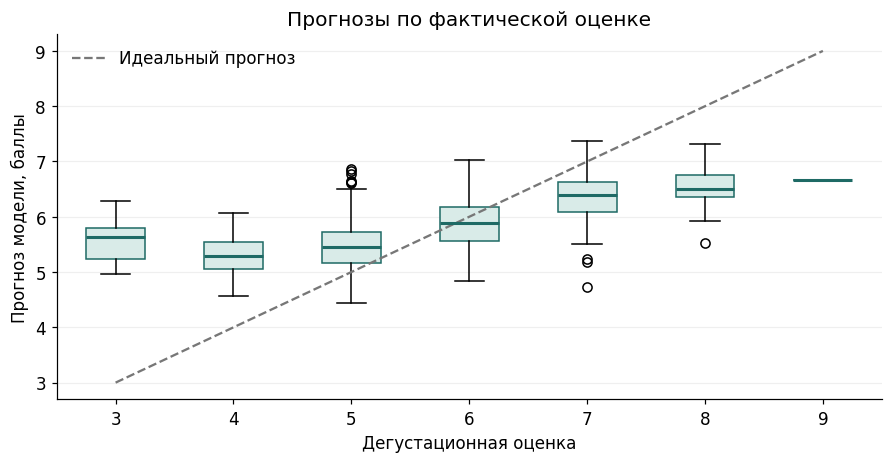

In [8]:
test = pd.DataFrame({
    "Тип вина": X_test["type"].map(labels),
    "Оценка": y_test,
    "Прогноз": test_pred,
    "Абс. ошибка": errors,
    "Смещение": test_pred - y_test.to_numpy(),
})

by_type = test.groupby("Тип вина").agg(
    **{"Образцов": ("Оценка", "size"), "MAE": ("Абс. ошибка", "mean")},
)
by_score = test.groupby("Оценка").agg(
    **{
        "Образцов": ("Оценка", "size"),
        "MAE": ("Абс. ошибка", "mean"),
        "Средний прогноз": ("Прогноз", "mean"),
        "Смещение": ("Смещение", "mean"),
    },
)
display(by_type.round(3), by_score.round(3))

fig, ax = plt.subplots(figsize=(8, 4.1), layout="constrained")
levels = by_score.index.to_numpy()
ax.boxplot([test.loc[test["Оценка"].eq(level), "Прогноз"] for level in levels],
           positions=levels, widths=0.5, patch_artist=True,
           boxprops={"facecolor": "#D9EBE8", "edgecolor": "#1E6A65"},
           medianprops={"color": "#1E6A65", "linewidth": 2})
ax.plot(levels, levels, linestyle="--", color="#777777", label="Идеальный прогноз")
ax.set(title="Прогнозы по фактической оценке", xlabel="Дегустационная оценка",
       ylabel="Прогноз модели, баллы")
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False)
plt.show()

### Какие признаки помогают прогнозу

Перемешиваем один столбец тестовой выборки за раз и измеряем, насколько увеличивается MAE. Значения отражают чувствительность обученной модели. Взаимосвязанные признаки могут частично заменять друг друга, поэтому их вклад трудно оценить по отдельности.

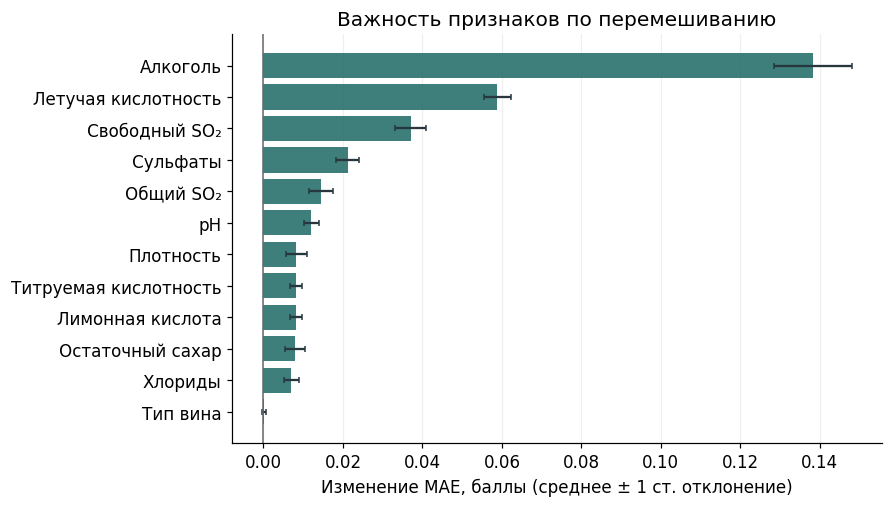

In [9]:
with threadpool_limits(limits=2):
    permutation = permutation_importance(best_model, X_test, y_test, n_repeats=12,
                                         scoring="neg_mean_absolute_error", random_state=SEED)
importance = pd.DataFrame({
    "Среднее": permutation.importances_mean,
    "Ст. отклонение": permutation.importances_std,
}, index=X_test.columns.map(features_ru)).sort_values("Среднее")

fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
ax.barh(importance.index, importance["Среднее"], xerr=importance["Ст. отклонение"],
        color="#1E6A65", alpha=0.86, error_kw={"ecolor": "#28363D", "capsize": 2})
ax.axvline(0, color="#646970", linewidth=1)
ax.set(title="Важность признаков по перемешиванию",
       xlabel="Изменение MAE, баллы (среднее ± 1 ст. отклонение)")
ax.grid(axis="x", alpha=0.2)
plt.show()

Наибольший рост MAE вызывает перемешивание содержания алкоголя, затем летучей кислотности и свободного диоксида серы. Для красного и белого вина MAE близки (0,516 и 0,545 балла). Модель завышает низкие оценки и занижает высокие, поэтому на пилоте особенно важно собрать больше таких примеров. В тесте всего шесть оценок 3 и одна оценка 9.

## 6. Внедрение

Сохраняем обученный пайплайн с перечнем входных столбцов и версией scikit-learn. Пример загружает его и получает прогнозы для двух образцов. Для рабочего использования нужно передавать тип вина и все 11 измерений в единицах датасета. Прогноз возвращается в баллах с одним знаком после запятой.

In [10]:
MODEL_PATH = Path("wine_quality_model.joblib")
joblib.dump({
    "pipeline": best_model,
    "feature_columns": X_train.columns.tolist(),
    "numeric_columns": numeric_features,
    "sklearn_version": sklearn.__version__,
}, MODEL_PATH, compress=3)


def predict_quality(samples, artifact):
    inputs = samples[artifact["feature_columns"]].copy()
    if not inputs["type"].isin(["red", "white"]).all():
        raise ValueError("Для каждого образца укажите тип red или white.")
    for column in artifact["numeric_columns"]:
        inputs[column] = pd.to_numeric(inputs[column], errors="raise")
    if not np.isfinite(inputs[artifact["numeric_columns"]].to_numpy(dtype=float)).all():
        raise ValueError("Для каждого образца нужны все 11 конечных числовых измерений.")
    return pd.Series(artifact["pipeline"].predict(inputs), index=inputs.index,
                     name="Прогноз качества")


artifact = joblib.load(MODEL_PATH)
example = X_test.groupby("type", sort=True).head(1)
prediction = predict_quality(example, artifact)
np.testing.assert_allclose(prediction, best_model.predict(example))
print(f"Сохранён пайплайн {MODEL_PATH.name} для scikit-learn {artifact['sklearn_version']}.")
display(example[["type", "alcohol", "pH"]].join(prediction.round(1)).reset_index(drop=True))

Сохранён пайплайн wine_quality_model.joblib для scikit-learn 1.7.2.


,type,alcohol,pH,Прогноз качества
0,white,10.6,3.16,5.6
1,red,9.8,3.28,5.2


**План пилота.** Проверить пайплайн на новых партиях Vinho Verde с оценками комиссии. Сравнивать MAE с медианным прогнозом в целом и отдельно по типам вина, отслеживать долю пропусков и сдвиг распределений измерений относительно обучения. Если выигрыш по MAE падает ниже 10 %, проверить состав новых партий и качество измерений перед переобучением.

**Область применения.** Результаты относятся к образцам Vinho Verde из этого набора. Потребуется отдельная проверка на винах других регионов и на новых партиях. Идентификаторов партий в данных нет, поэтому тест измеряет качество на других профилях из той же выборки.

### Источники

- Объединённый датасет и описание признаков. [Wine Quality на Kaggle](https://www.kaggle.com/datasets/rajyellow46/wine-quality)
- Cortez, P., Cerdeira, A., Almeida, F., Matos, T., & Reis, J. (2009). *Modeling wine preferences by data mining from physicochemical properties*. Decision Support Systems, 47(4), 547–553. [Статья](https://doi.org/10.1016/j.dss.2009.05.016) · [Датасет UCI](https://doi.org/10.24432/C56S3T)